In [1]:
# import necessary libraries
import os
import cv2
from tensorflow import keras
import numpy as np
import pandas as pd
import seaborn as sn

import tensorflow as tf
import matplotlib.pyplot as plt
from keras.optimizers import Adam
from keras.models import Sequential
from sklearn.metrics import classification_report,confusion_matrix
from keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout
from pathlib import Path
import json
from tensorflow.keras.models import model_from_json
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import model_from_json

In [2]:
# class names are read to a list from the dataset subfolder names 
categories = os.listdir('fishdataset/test_set')
img_size = 256

In [3]:
# load the images to the memory and reshape them according to img_size
def get_data(data_dir):
    data = [] 
    for category in categories: 
        path = os.path.join(data_dir, category)
        class_num = categories.index(category)
        for img in os.listdir(path):
            try:
                img_arr = cv2.imread(os.path.join(path, img))#[...,::-1] #convert BGR to RGB format
                resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshaping images to preferred size
                data.append([resized_arr, class_num])
            except Exception as e:
                print(e)
    return np.array(data, dtype=object)

In [4]:
train = get_data('fishdataset/train_set')
val = get_data('fishdataset/test_set')

In [5]:
# prepare the labels of training and validation data
x_train = []
y_train = []
x_val = []
y_val = []

for feature, label in train:
  x_train.append(feature)
  y_train.append(label)

for feature, label in val:
  x_val.append(feature)
  y_val.append(label)

In [6]:
# normalize the data
x_train = np.array(x_train) / 255
x_val = np.array(x_val) / 255

x_train.reshape(-1, img_size, img_size, 1)
y_train = np.array(y_train)

x_val.reshape(-1, img_size, img_size, 1)
y_val = np.array(y_val)

In [7]:
# call mobilenetv2 as the base model
base_model = tf.keras.applications.MobileNetV2(input_shape = (256, 256, 3), include_top = False, weights = "imagenet")
base_model.trainable = False

In [19]:
# add pooling, dropout and output layer
model = tf.keras.Sequential([base_model, tf.keras.layers.GlobalAveragePooling2D(), tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(20, activation="softmax")])
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_224 (Func  (None, 8, 8, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d_1  (None, 1280)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dropout_1 (Dropout)         (None, 1280)              0         
                                                                 
 dense_1 (Dense)             (None, 20)                25620     
                                                                 
Total params: 2283604 (8.71 MB)
Trainable params: 25620 (100.08 KB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________


In [20]:
base_learning_rate = 0.0001

# compile and train the model on the training dataset
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])

history = model.fit(x_train,y_train,epochs = 100, validation_data = (x_val, y_val))

Epoch 1/100
7/7 [==============================] - 5s 424ms/step - loss: 3.7262 - accuracy: 0.0000e+00 - val_loss: 3.3283 - val_accuracy: 0.0000e+00
Epoch 2/100
7/7 [==============================] - 2s 314ms/step - loss: 3.2643 - accuracy: 0.0333 - val_loss: 2.9151 - val_accuracy: 0.0667
Epoch 3/100
7/7 [==============================] - 2s 302ms/step - loss: 2.8745 - accuracy: 0.0905 - val_loss: 2.5490 - val_accuracy: 0.1556
Epoch 4/100
7/7 [==============================] - 2s 301ms/step - loss: 2.5141 - accuracy: 0.1667 - val_loss: 2.2426 - val_accuracy: 0.1778
Epoch 5/100
7/7 [==============================] - 2s 295ms/step - loss: 2.2009 - accuracy: 0.2810 - val_loss: 1.9989 - val_accuracy: 0.1889
Epoch 6/100
7/7 [==============================] - 2s 291ms/step - loss: 1.9232 - accuracy: 0.3381 - val_loss: 1.8108 - val_accuracy: 0.2000
Epoch 7/100
7/7 [==============================] - 2s 292ms/step - loss: 1.8265 - accuracy: 0.3095 - val_loss: 1.6641 - val_accuracy: 0.2333
Epoch

### Plotting

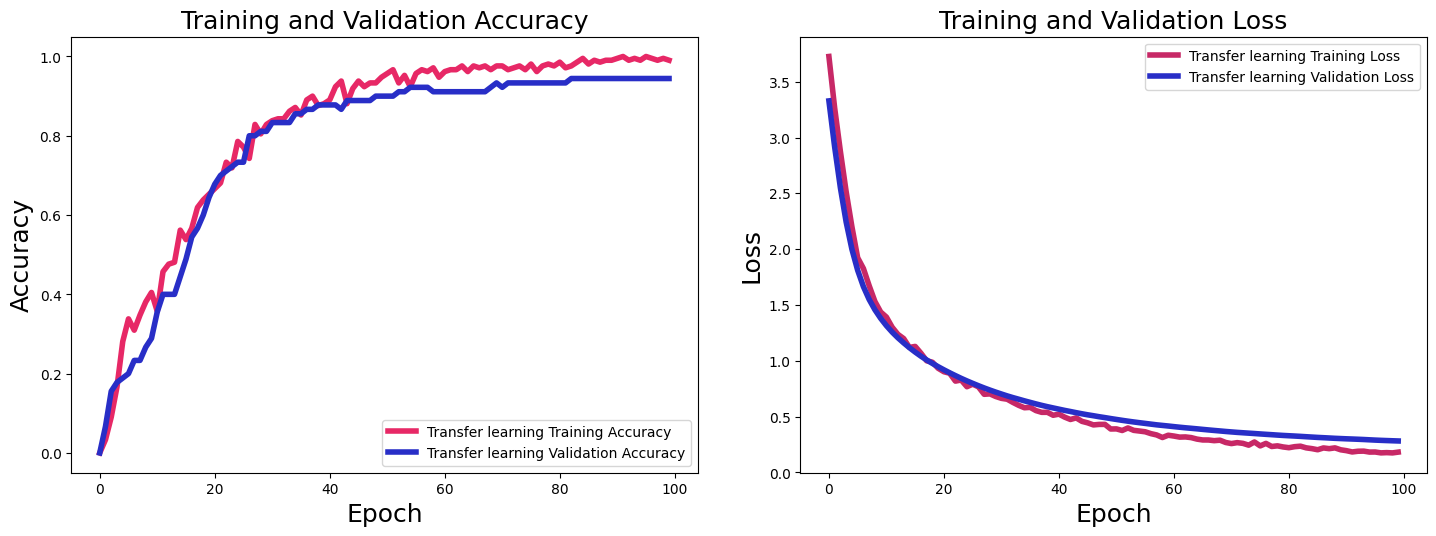

In [34]:
epochs_range = range(100)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(15,6))
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

ax1.plot(epochs_range, acc, label='Transfer learning Training Accuracy', c = '#e72866', linewidth=4)
ax1.plot(epochs_range, val_acc, label='Transfer learning Validation Accuracy', c='#282ec7', linewidth=4)

ax1.legend()
ax1.set_title('Training and Validation Accuracy',fontsize=18)
ax1.set_ylabel('Accuracy',fontsize=18)
ax1.set_xlabel('Epoch',fontsize=18)


ax2.plot(epochs_range, loss, label='Transfer learning Training Loss',c = '#c72866', linewidth=4)
ax2.plot(epochs_range, val_loss, label='Transfer learning Validation Loss', c='#282ec7', linewidth=4)

ax2.legend()
ax2.set_title('Training and Validation Loss',fontsize=18)
ax2.set_ylabel('Loss',fontsize=18)
ax2.set_xlabel('Epoch',fontsize=18)
fig.tight_layout(pad=3.0)
plt.show()

### Classification Report

In [22]:
# make predictions with the validation data
predictions = model.predict(x_val)
predictions = np.argmax(predictions, axis=1)  # Assuming you are using softmax activation
print(predictions.shape)  # Check the shape of predictions

print(classification_report(y_val, predictions, target_names=categories))

3/3 [==============================] - 1s 191ms/step
(90,)
              precision    recall  f1-score   support

     arowana       0.90      0.93      0.92        30
   gold fish       1.00      0.90      0.95        30
  guppy fish       0.94      1.00      0.97        30

    accuracy                           0.94        90
   macro avg       0.95      0.94      0.94        90
weighted avg       0.95      0.94      0.94        90



In [24]:
# save neural network structure
model_structure = model.to_json()
f = Path("model_structure.json")
f.write_text(model_structure)

# save neural network's trained weights
model.save_weights("model_weights.h5")

In [25]:
# save class names
with open("categories.json", "w") as f:
    f.write(json.dumps(categories))

In [30]:
# set a confidence threshold
confidence_threshold = 0.5

# load the class names from saved files
# open the JSON file
with open('categories.json') as json_file:
    # Load the JSON data from the file
    data = json.load(json_file)

# convert the JSON data to a Python list
categories = list(data)

In [14]:
# load the json file that contains the model's structure
f = Path("model_structure.json")
model_structure = f.read_text()

In [15]:
# recreate the Keras model object from the json data
model = model_from_json(model_structure)

# re-load the model's trained weights
model.load_weights("model_weights.h5")

1/1 [==============================] - 0s 32ms/step
gold fish


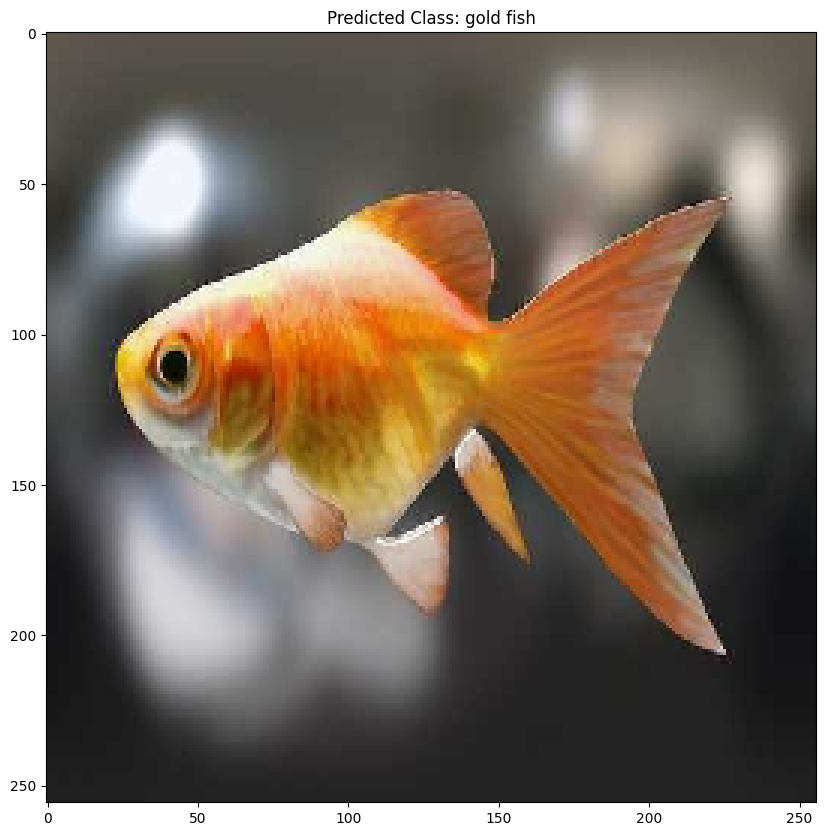

In [32]:
# Load an image file to test, resizing as required by this model
img_size = 256
image_path = '1CSUFIA1U6IB.jpg'
img = image.load_img(image_path, target_size=(img_size, img_size))

# Convert the image to a numpy array
image_array = image.img_to_array(img)

# Add a fourth dimension to the image (since Keras expects a bunch of images, not a single image)
images = np.expand_dims(image_array, axis=0)
images = preprocess_input(images)

# Get the prediction probabilities
results = model.predict(images)

# Get the class index with the highest probability
class_index = np.argmax(results)

# Check if the highest probability is above the confidence threshold
if results[0][class_index] < confidence_threshold:
    predicted_class = "unknown"
else:
    predicted_class = categories[class_index]

# Print the class predictions
print(predicted_class)

# Display the image with the predicted class
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(img)
ax.set_title("Predicted Class: " + predicted_class)
plt.show()